[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/23_vae.ipynb)

# 23 · Variational Autoencoders: Generating New Data From a Learned Latent Space

**Part 4 — Deep generative & representation learning** · Notebook 23 of 27

Classifiers answer "what is this?". A **generative model** answers a harder question: "what does data like this look like?", well enough to produce new examples that never existed. We met two simple generative models already: the Gaussian mixture (notebook 15), whose hidden variable is a discrete cluster label, and probabilistic PCA (notebook 16), whose hidden variable is a continuous vector mapped *linearly* to the data. Both generated blurry, unconvincing digits.

The **variational autoencoder** (VAE; Kingma & Welling, 2013) keeps PPCA's recipe (draw a hidden vector $z \sim \mathcal{N}(0, I)$, then generate $x$ from it) but replaces the linear map with a neural network. That makes the likelihood impossible to compute exactly, and the way around it combines three ideas we've built separately: the **ELBO** from EM (notebook 15), **neural networks** trained by backprop (notebooks 19–20), and one new trick, **reparameterization**, that lets gradients flow through random sampling. This is CX 4240 lecture 17's capstone of the probabilistic pipeline.

**What you'll learn**

1. From mixtures to deep latent variable models
2. Why maximum likelihood is now intractable
3. The plain autoencoder, and why it can't generate
4. The ELBO, again: an encoder that does approximate inference
5. The reparameterization trick
6. A VAE in PyTorch, trained on Fashion-MNIST
7. The latent space: a map of clothing
8. Generating, interpolating, and the role of the prior
9. The β knob: reconstruction vs. regularity
10. Limits (blur, posterior collapse) and what came next: VQ-VAE, GANs, diffusion

*Course map: CX 4240 lecture 17 (latent variable models: from GMMs to deep latent variable models, deep Gaussian LVMs, sampling as generation, intractable MLE, the ELBO, the autoencoder intuition, stochastic gradients and the reparameterization trick, VAE generation, GANs and diffusion) and lecture 18/21 (probabilistic PCA as an LVM; reconstruction and generation as pretext tasks for representation learning); ISYE 4600 W10 (autoencoders, the PCA connection, VAEs and GANs).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, gzip, os, urllib.request
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def load_fashion_mnist(root="data/fashion"):
    os.makedirs(root, exist_ok=True); out = {}
    for split, prefix in [("train", "train"), ("test", "t10k")]:
        for kind, offset in [("images", 16), ("labels", 8)]:
            fname = f"{prefix}-{kind}-idx{3 if kind == 'images' else 1}-ubyte.gz"; path = os.path.join(root, fname)
            if not os.path.exists(path): urllib.request.urlretrieve(FMNIST_URL + fname, path)
            out[(split, kind)] = np.frombuffer(gzip.open(path).read(), np.uint8, offset=offset)
    return (out[("train", "images")].reshape(-1, 784), out[("train", "labels")], out[("test", "images")].reshape(-1, 784), out[("test", "labels")])

Xtr_np, ytr_np, Xte_np, yte_np = load_fashion_mnist()
N_TRAIN = 20000                                   # 60000 on a GPU runtime
Xtr = torch.tensor(Xtr_np[:N_TRAIN], dtype=torch.float32) / 255; ytr = ytr_np[:N_TRAIN]
Xte = torch.tensor(Xte_np, dtype=torch.float32) / 255
print(f"PyTorch on {device}; {len(Xtr):,} training images (pixels in [0, 1])")
print("Ready ✓")

Setup complete ✓


PyTorch on cpu; 20,000 training images (pixels in [0, 1])
Ready ✓


---
## 1. From mixtures to deep latent variable models

CX lecture 17 walks the path from the GMM. A **latent variable model** says each data point $x$ was produced from a hidden variable $z$:

$$p_\theta(x) = \int p(z)\,p_\theta(x \mid z)\,dz.$$

| Model | Hidden $z$ | How $x$ is generated from $z$ |
|---|---|---|
| GMM (notebook 15) | a cluster label, $K$ values | $\mathcal{N}(\mu_z, \Sigma_z)$: one Gaussian per label |
| Probabilistic PCA (notebook 16) | $z \sim \mathcal{N}(0, I_k)$ | $\mathcal{N}(Wz + \mu, \sigma^2 I)$: a **linear** map |
| **Deep latent variable model** | $z \sim \mathcal{N}(0, I_k)$ | $p_\theta(x \mid z)$ whose parameters are a **neural network** $f_\theta(z)$ |

Think of it as a GMM with **infinitely many components**, one for every point in a continuous latent space, whose centers lie on a curved surface traced out by the network (CX: *"GMMs: not flexible enough → infinite-many components: continuous z → make more flexible: deep models"*). **Sampling is generation**: draw $z$ from the prior, push it through the network.

For images with pixel values in [0, 1], a convenient $p_\theta(x \mid z)$ treats each pixel as a Bernoulli (or continuous Bernoulli) variable with mean given by the network's sigmoid output; its negative log-likelihood is the **binary cross-entropy** between the image and the network's output. With a Gaussian $p_\theta(x \mid z)$ it would be squared error instead.

---
## 2. Why maximum likelihood is now intractable

To fit $\theta$ by maximum likelihood we need $\log p_\theta(x) = \log\int p(z)p_\theta(x \mid z)\,dz$. For the GMM the integral was a sum of $K$ terms; for PPCA it had a closed form because everything was linear and Gaussian. With a neural network inside, there's no closed form.

The obvious numerical fix, Monte Carlo (draw many $z$ from the prior and average $p_\theta(x \mid z)$), fails in practice: for a specific image $x$, almost every random $z$ produces something completely different, with likelihood indistinguishable from zero. The few $z$ values that actually explain $x$ occupy a tiny region of latent space, and blind sampling almost never hits it. A small illustration in 2-D:

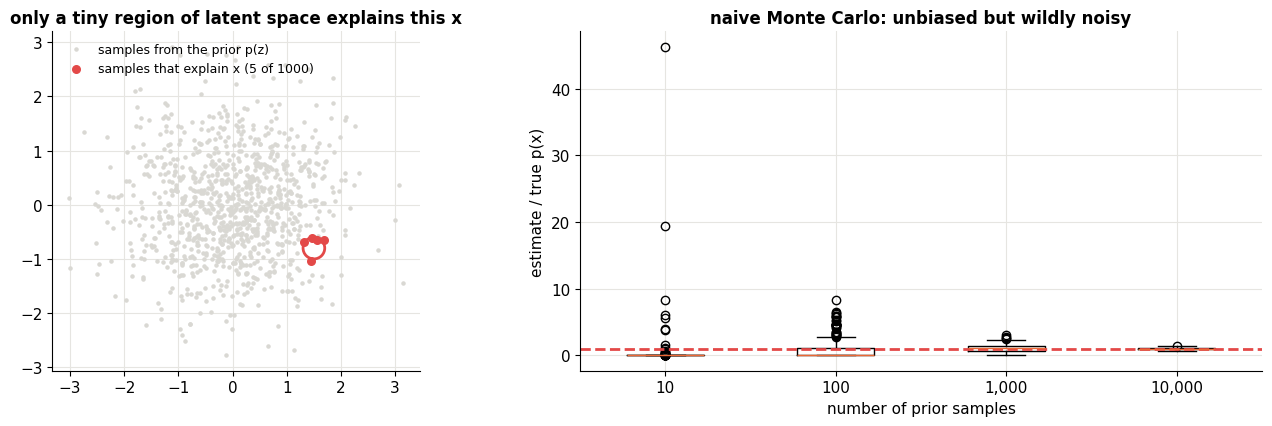

In [2]:
r_ = np.random.default_rng(0)
# A latent space where only a small region explains a given observation x: p(x|z) is a narrow bump around z* = (1.5, -0.8)
z_star, width = np.array([1.5, -0.8]), 0.08
lik = lambda Z: np.exp(-((Z - z_star) ** 2).sum(-1) / (2 * width ** 2))
true_px = 2 * np.pi * width ** 2 * np.exp(-(z_star ** 2).sum() / 2) / (2 * np.pi)    # exact ∫ N(z;0,I) lik(z) dz (small-width approximation)
estimates = {n: [lik(r_.normal(size=(n, 2))).mean() for _ in range(200)] for n in [10, 100, 1000, 10000]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
Z = r_.normal(size=(1000, 2)); hit = lik(Z) > 0.01
axes[0].scatter(*Z[~hit].T, s=5, color=C["light"], label="samples from the prior p(z)")
axes[0].scatter(*Z[hit].T, s=30, color=C["red"], label=f"samples that explain x ({hit.sum()} of 1000)")
axes[0].add_patch(plt.Circle(z_star, 2.5 * width, fill=False, color=C["red"], lw=2))
axes[0].set(aspect="equal", title="only a tiny region of latent space explains this x"); axes[0].legend(fontsize=9, loc="upper left")
axes[1].boxplot([np.array(v) / true_px for v in estimates.values()]); axes[1].set_xticks(range(1, len(estimates) + 1), [f"{n:,}" for n in estimates]); axes[1].axhline(1, color=C["red"], ls="--")
axes[1].set(xlabel="number of prior samples", ylabel="estimate / true p(x)", title="naive Monte Carlo: unbiased but wildly noisy")
fig.tight_layout(); plt.show()

With 10 samples the estimate is usually 0 (no sample landed in the red circle) and occasionally 20 to 40 times too big; even with 100 it routinely misses by a factor of several. In 2-D, thousands of samples eventually work; in a 16- or 100-dimensional latent space, the useful region is an exponentially smaller fraction of the prior, and blind sampling is hopeless.

The fix is to sample $z$ **where it matters**: from a distribution concentrated on the $z$'s that explain this particular $x$, i.e. the posterior $p_\theta(z \mid x)$. We can't compute that posterior either, but we can **learn an approximation** to it. That's the encoder.

---
## 3. The plain autoencoder, and why it can't generate

CX lecture 17 gives the intuition first: an **autoencoder** (ISYE W10). An **encoder** network compresses an image into a short code $z$, a **decoder** network reconstructs the image from the code, and both are trained to make the reconstruction match the input. With linear layers and squared error, the best autoencoder recovers exactly the PCA subspace (notebook 16). With nonlinear networks it can learn curved, much more compact representations. Let's train one with a **2-dimensional** code, so we can draw the code space:

autoencoder trained in 36s


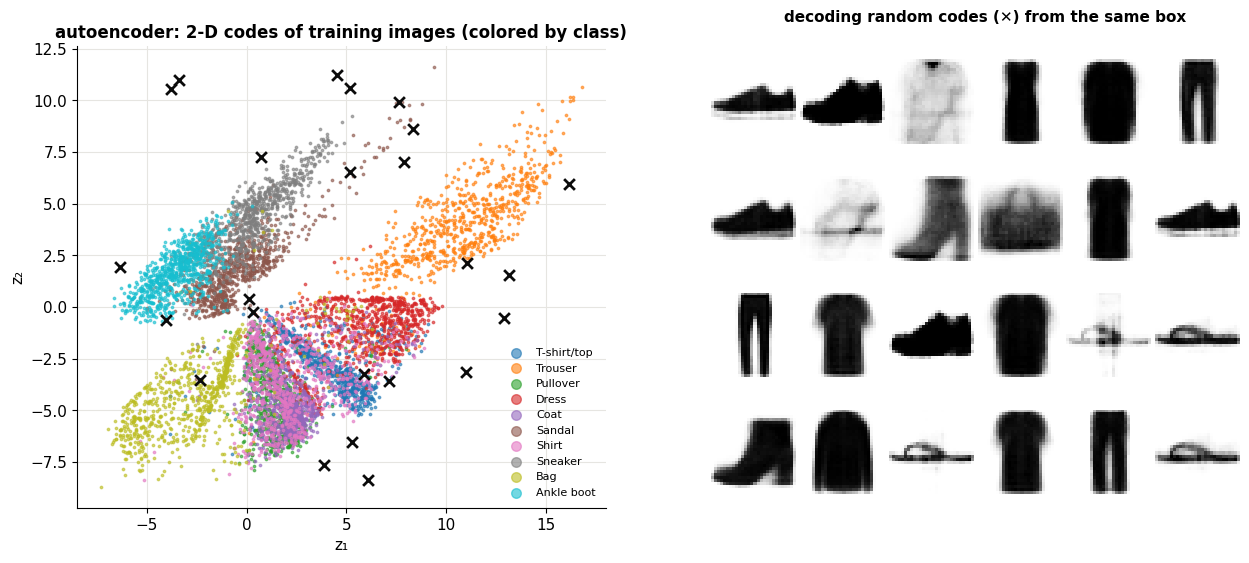

In [3]:
class Encoder(nn.Module):
    def __init__(self, z_dim, hidden=512, variational=True):
        super().__init__(); self.variational = variational
        self.body = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 256), nn.ReLU())
        self.mu = nn.Linear(256, z_dim); self.logvar = nn.Linear(256, z_dim) if variational else None
    def forward(self, x):
        h = self.body(x); return (self.mu(h), self.logvar(h)) if self.variational else self.mu(h)

class Decoder(nn.Module):
    def __init__(self, z_dim, hidden=512):
        super().__init__(); self.net = nn.Sequential(nn.Linear(z_dim, 256), nn.ReLU(), nn.Linear(256, hidden), nn.ReLU(), nn.Linear(hidden, 784))
    def forward(self, z): return self.net(z)          # logits; sigmoid gives pixel means

def train_ae(z_dim=2, epochs=15, seed=0):
    torch.manual_seed(seed); enc, dec = Encoder(z_dim, variational=False).to(device), Decoder(z_dim).to(device)
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=1e-3)
    for ep in range(epochs):
        for idx in torch.randperm(len(Xtr)).split(128):
            x = Xtr[idx].to(device); loss = F.binary_cross_entropy_with_logits(dec(enc(x)), x, reduction="sum") / len(x)
            opt.zero_grad(); loss.backward(); opt.step()
    return enc, dec

t0 = time.time(); ae_enc, ae_dec = train_ae(); print(f"autoencoder trained in {time.time() - t0:.0f}s")
with torch.no_grad(): Z_ae = ae_enc(Xtr.to(device)).cpu().numpy()

cmap10 = plt.get_cmap("tab10")
def plot_codes(ax, Z, title):
    for c in range(10):
        ax.scatter(*Z[ytr == c][:800].T, s=3, color=cmap10(c), label=CLASSES[c], alpha=0.6)
    ax.set(title=title, xlabel="z₁", ylabel="z₂")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_codes(axes[0], Z_ae, "autoencoder: 2-D codes of training images (colored by class)")
axes[0].legend(markerscale=4, fontsize=8, loc="best")
lo, hi = Z_ae.min(0), Z_ae.max(0)
rand_z = torch.tensor(np.random.default_rng(1).uniform(lo, hi, size=(24, 2)), dtype=torch.float32)
with torch.no_grad(): gen = torch.sigmoid(ae_dec(rand_z.to(device))).cpu().numpy()
axes[0].scatter(*rand_z.numpy().T, marker="x", s=60, color=C["ink"], label="random codes")
gs_ = axes[1].get_subplotspec().subgridspec(4, 6, wspace=0.05, hspace=0.05); axes[1].remove()
for k in range(24):
    a = fig.add_subplot(gs_[k // 6, k % 6]); a.imshow(gen[k].reshape(28, 28), cmap="gray_r"); a.axis("off")
fig.text(0.73, 0.92, "decoding random codes (✕) from the same box", ha="center", fontsize=11, weight="bold")
plt.show()

---
> 🚧 **This notebook is being written section by section.** The sections above are complete and run top to bottom; more are on the way.